Enter PH (4-10): 

 5


Enter Temperature (10-40): 

 23


Enter Initial Population (100-1,000,000): 

 400


Enter Nutrient Available (1-10): 

 3


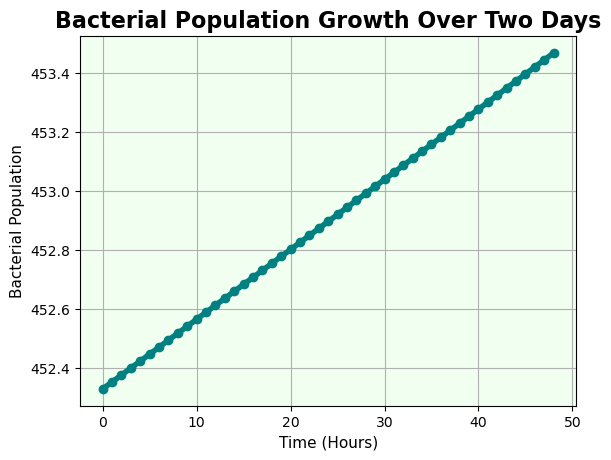

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
KS = 3.5 ## Half saturation constant
UREF = 3.6 #Reference growth rate
OPH = 7.1 #Optimal pH
print("\033[92mEnter PH (4-10): \033[0m", end="")
userPH = float(input()) 
OT = 27 # Optimal Temp
print("\033[92mEnter Temperature (10-40): \033[0m", end="")
userTemp = float(input())
tempConst = 0.02773 #approximation from optimal temp and diff at 50 degrees
deltaT = abs(userTemp - OT)
lagTime = 1.5 + 4.5*(deltaT)
pHSens = 0.7 # pH sensitivity constant 
print("\033[92mEnter Initial Population (100-1,000,000): \033[0m", end="")
initialPop = float(input()) 
print("\033[92mEnter Nutrient Available (1-10): \033[0m", end="")
nutrientAvail = float(input()) 
growthConstant = 0.0; #growth constant in response to nutrient availability
if (nutrientAvail >= 1 and nutrientAvail <= 5):
	growthConstant = 2 + 0.5*(nutrientAvail - 1)
elif(nutrientAvail > 5 and nutrientAvail <= 10):
    growthConstant = 4 + 0.4*(nutrientAvail - 5)
a = initialPop*(growthConstant - 1) #max increase in bacterial population above the initial population
fPH = np.exp(-pHSens*(userPH - OPH)**2) #effect of pH on the growth rate
fT = np.exp(-tempConst * (userTemp - OT)**2) #effect of the temp on the growth rate
fS =  nutrientAvail / (KS + nutrientAvail) #effect of the nutrient availability on the growth rate
uMax = (UREF)*fPH*fT*fS #max growth rate given the bounds
times = np.arange(0, 49, 1) #49 points from 0-48
population_values = []
for t in times:
    x = (uMax * np.e * (lagTime - t)) / a + 1 #bacterial population at a specific time
    N = initialPop + a*(np.exp(-np.exp(x))) #population change in response to all the conditions at a specific time
    population_values.append(N)
plt.plot(times, population_values, marker='o', linestyle='-', color='teal', linewidth=4)
plt.title("Bacterial Population Growth Over Two Days",fontsize=16, fontweight='bold')
plt.xlabel("Time (Hours)", fontsize=11)
plt.ylabel("Bacterial Population", fontsize=11)
plt.gca().set_facecolor('honeydew')
plt.grid(True)
plt.show()